In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

In [2]:
digits = load_digits()
X = pd.DataFrame(digits.data, columns=[f"pixel_{i}" for i in range(64)])
y = pd.Series(digits.target, name="digit")

print("Shape (samples, features):", X.shape)
print("Number of classes:", y.nunique())
print("Missing values:", X.isnull().sum().sum())
print("Pixel value range:", X.values.min(), "to", X.values.max())
X.head()

Shape (samples, features): (1797, 64)
Number of classes: 10
Missing values: 0
Pixel value range: 0.0 to 16.0


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_54,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,5.0,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,9.0,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0


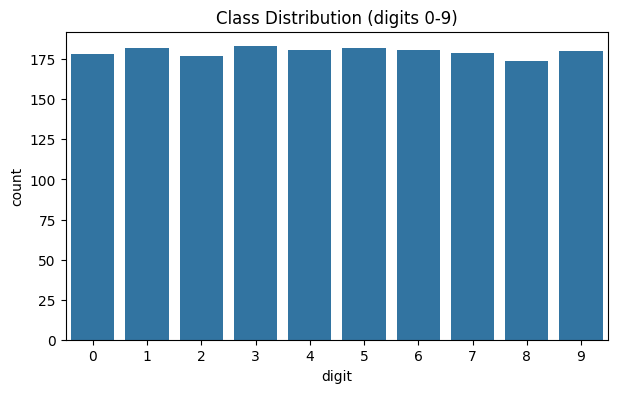

digit
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64


In [3]:
# Class distribution
plt.figure(figsize=(7, 4))
sns.countplot(x=y)
plt.title("Class Distribution (digits 0-9)")
plt.show()
print(y.value_counts().sort_index())

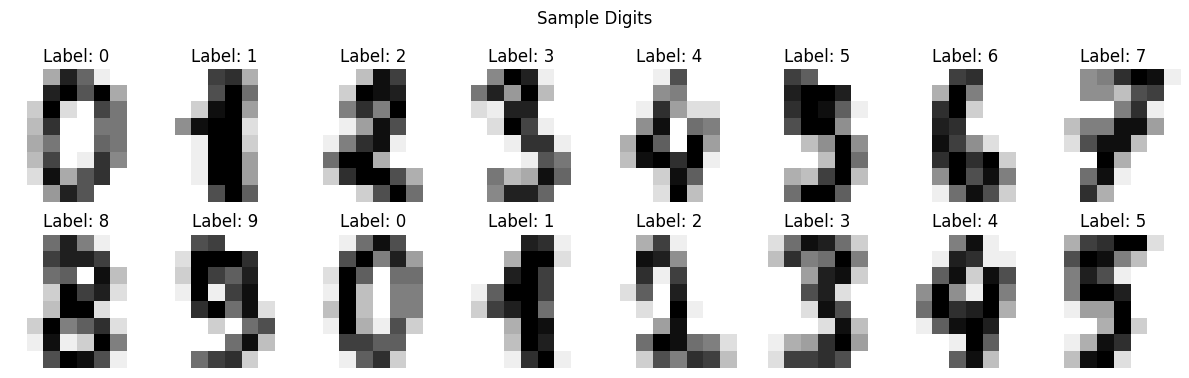

In [4]:
# Look at some sample images
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for ax, img, label in zip(axes.ravel(), digits.images, digits.target):
    ax.imshow(img, cmap="gray_r")
    ax.set_title(f"Label: {label}")
    ax.axis("off")
plt.suptitle("Sample Digits")
plt.tight_layout()
plt.show()

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (1257, 64)
Testing set : (540, 64)


In [6]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN (k=5)":           make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Naive Bayes":         GaussianNB(),
    "Decision Tree":       DecisionTreeClassifier(random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM (RBF)":           make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale")),
}

rows, predictions = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred

    acc = accuracy_score(y_test, pred)
    rows.append({
        "Algorithm": name,
        "Accuracy": acc,
        "Error Rate": 1 - acc,
        "Precision (macro)": precision_score(y_test, pred, average="macro"),
        "Recall (macro)": recall_score(y_test, pred, average="macro"),
        "F1-score (macro)": f1_score(y_test, pred, average="macro"),
    })

results = pd.DataFrame(rows).set_index("Algorithm").sort_values("Accuracy", ascending=False)
results.round(4)

  File "C:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                

,Accuracy,Error Rate,Precision (macro),Recall (macro),F1-score (macro)
Algorithm,,,,,
Logistic Regression,0.9815,0.0185,0.9816,0.9814,0.9814
SVM (RBF),0.9815,0.0185,0.9821,0.9812,0.9814
KNN (k=5),0.9704,0.0296,0.9709,0.9702,0.9702
Random Forest,0.9667,0.0333,0.9678,0.9663,0.9663
Decision Tree,0.8519,0.1481,0.8557,0.8518,0.8522
Naive Bayes,0.8222,0.1778,0.8526,0.8216,0.8259


In [7]:
# Show as percentages and highlight the best value in each column
styled = (results * 100).round(2).style.format("{:.2f}%")
styled = styled.highlight_max(subset=["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"], color="lightgreen")
styled = styled.highlight_min(subset=["Error Rate"], color="lightgreen")
styled

,Accuracy,Error Rate,Precision (macro),Recall (macro),F1-score (macro)
Algorithm,,,,,
Logistic Regression,98.15%,1.85%,98.16%,98.14%,98.14%
SVM (RBF),98.15%,1.85%,98.21%,98.12%,98.14%
KNN (k=5),97.04%,2.96%,97.09%,97.02%,97.02%
Random Forest,96.67%,3.33%,96.78%,96.63%,96.63%
Decision Tree,85.19%,14.81%,85.57%,85.18%,85.22%
Naive Bayes,82.22%,17.78%,85.26%,82.16%,82.59%


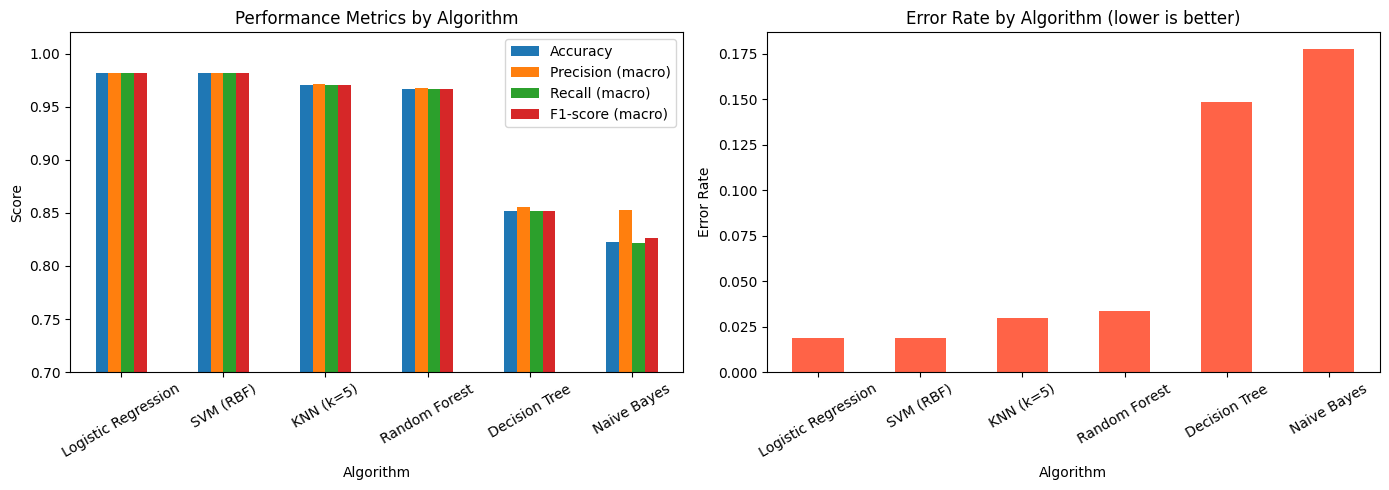

In [8]:
# Bar charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

results[["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"]].plot(
    kind="bar", ax=axes[0], ylim=(0.7, 1.02))
axes[0].set_title("Performance Metrics by Algorithm")
axes[0].set_ylabel("Score")
axes[0].tick_params(axis="x", rotation=30)

results["Error Rate"].plot(kind="bar", ax=axes[1], color="tomato")
axes[1].set_title("Error Rate by Algorithm (lower is better)")
axes[1].set_ylabel("Error Rate")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

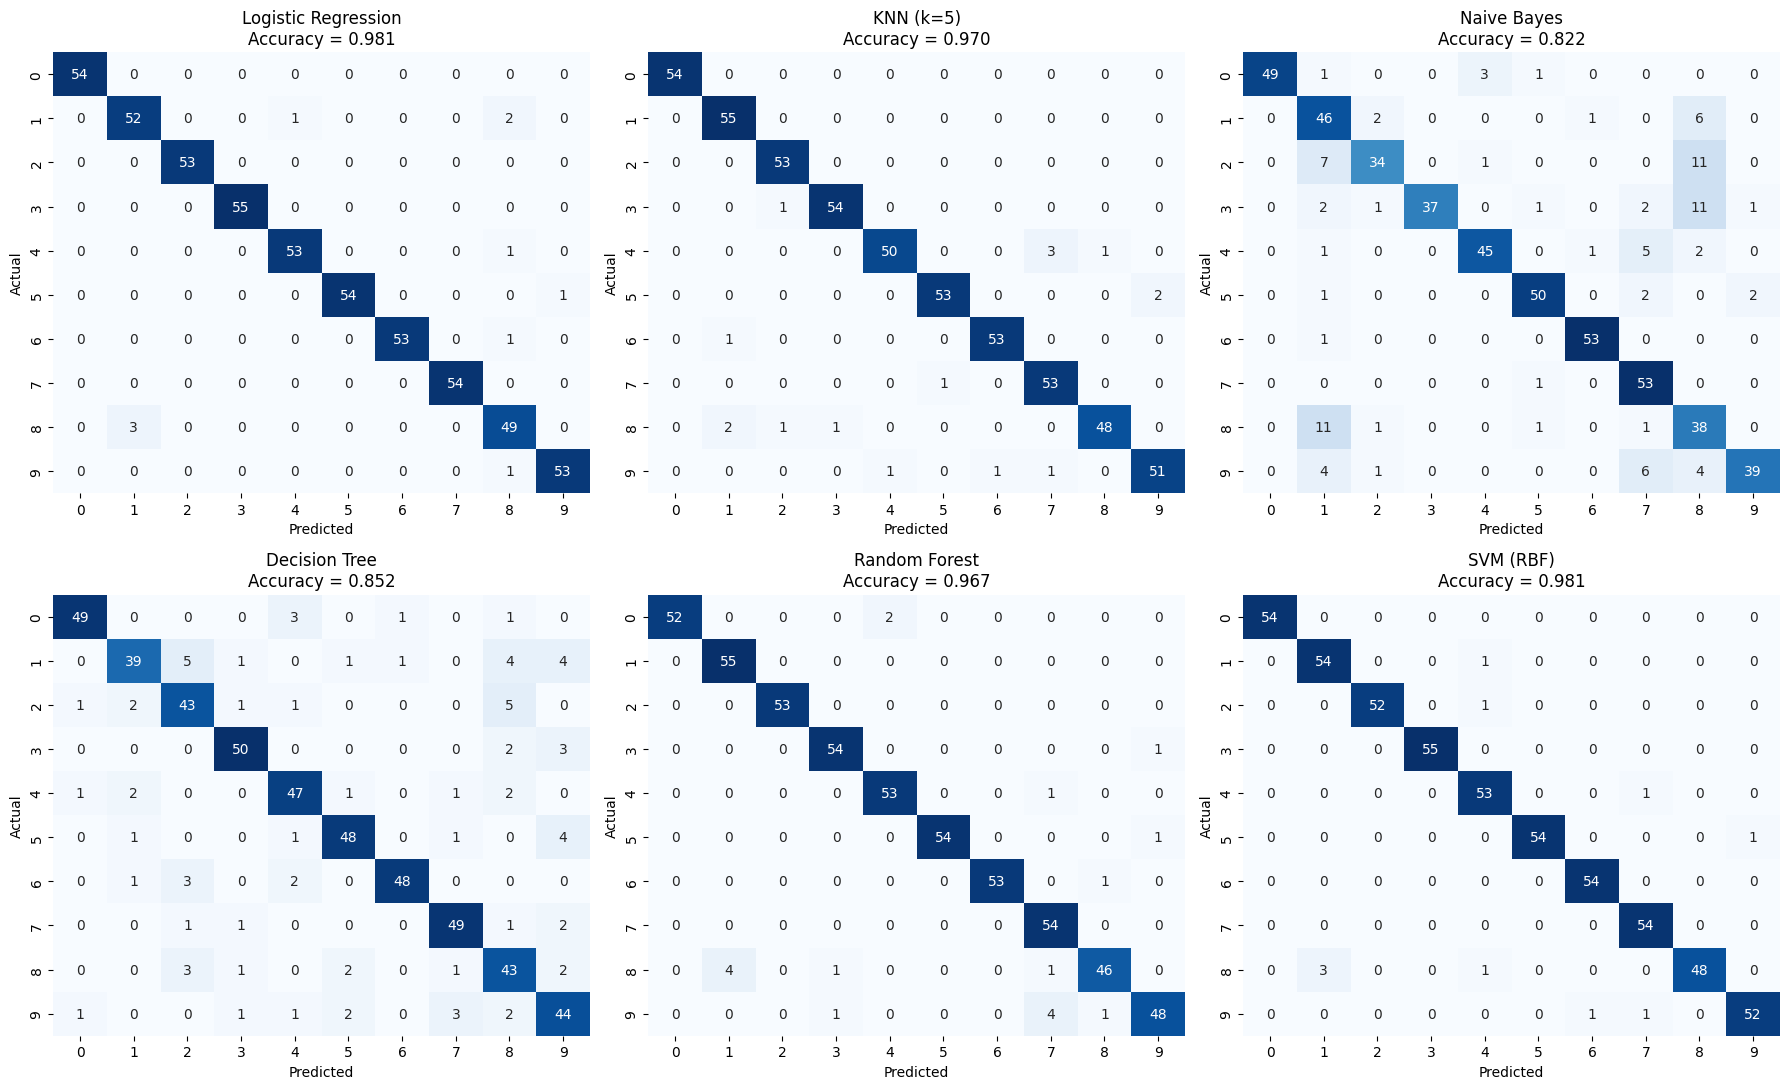

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{name}\nAccuracy = {accuracy_score(y_test, pred):.3f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

**How to read it:** rows = actual digit, columns = predicted digit. The diagonal shows correct predictions. Any number off the diagonal is an error (for example, row 8 / column 1 means an actual 8 was predicted as 1).

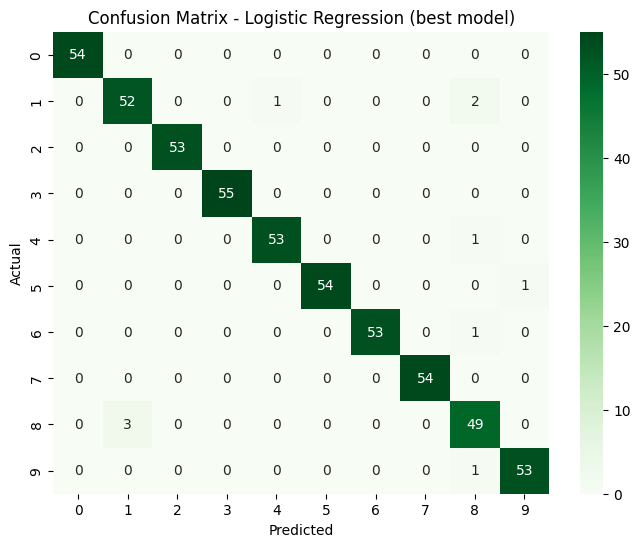

Most common mistakes:
  Actual 8 predicted as 1: 3 times
  Actual 1 predicted as 8: 2 times
  Actual 1 predicted as 4: 1 times
  Actual 4 predicted as 8: 1 times
  Actual 5 predicted as 9: 1 times


In [10]:
# Detailed look at the best model
best_name = results.index[0]
best_pred = predictions[best_name]
cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=range(10), yticklabels=range(10))
plt.title(f"Confusion Matrix - {best_name} (best model)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Most common mistakes
errors = [(i, j, cm[i, j]) for i in range(10) for j in range(10) if i != j and cm[i, j] > 0]
errors = sorted(errors, key=lambda e: e[2], reverse=True)[:5]
print("Most common mistakes:")
for actual, predicted, count in errors:
    print(f"  Actual {actual} predicted as {predicted}: {count} times")

In [11]:
# TP, FP, FN, TN for every class (from the confusion matrix)
total = cm.sum()
per_class = []
for c in range(10):
    TP = cm[c, c]
    FP = cm[:, c].sum() - TP
    FN = cm[c, :].sum() - TP
    TN = total - TP - FP - FN
    per_class.append({"Digit": c, "TP": TP, "FP": FP, "FN": FN, "TN": TN,
                      "Precision": TP / (TP + FP) if TP + FP else 0,
                      "Recall": TP / (TP + FN) if TP + FN else 0})
pd.DataFrame(per_class).set_index("Digit").round(4)

,TP,FP,FN,TN,Precision,Recall
Digit,,,,,,
0,54,0,0,486,1.0000,1.0000
1,52,3,3,482,0.9455,0.9455
2,53,0,0,487,1.0000,1.0000
3,55,0,0,485,1.0000,1.0000
4,53,1,1,485,0.9815,0.9815
5,54,0,1,485,1.0000,0.9818
6,53,0,1,486,1.0000,0.9815
7,54,0,0,486,1.0000,1.0000
8,49,5,3,483,0.9074,0.9423


## Step 7: Per-Class Precision and Recall (best model)

In [12]:
print(f"Classification report for {best_name}")
print(classification_report(y_test, best_pred, digits=4))

Classification report for Logistic Regression
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        54
           1     0.9455    0.9455    0.9455        55
           2     1.0000    1.0000    1.0000        53
           3     1.0000    1.0000    1.0000        55
           4     0.9815    0.9815    0.9815        54
           5     1.0000    0.9818    0.9908        55
           6     1.0000    0.9815    0.9907        54
           7     1.0000    1.0000    1.0000        54
           8     0.9074    0.9423    0.9245        52
           9     0.9815    0.9815    0.9815        54

    accuracy                         0.9815       540
   macro avg     0.9816    0.9814    0.9814       540
weighted avg     0.9818    0.9815    0.9816       540



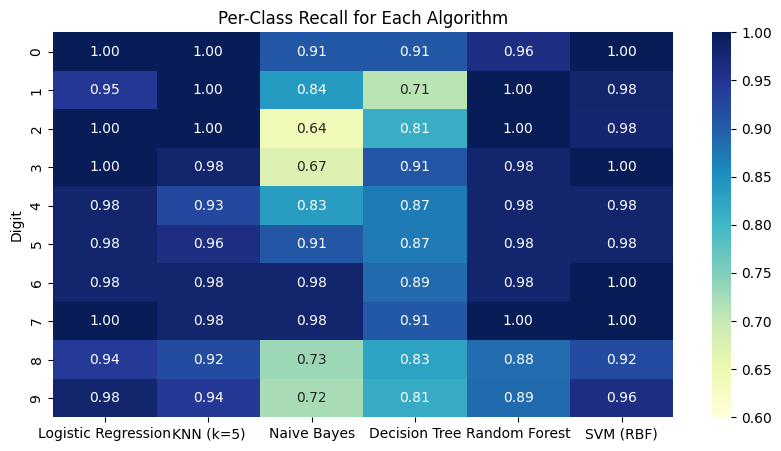

In [13]:
# Compare per-class recall across algorithms to find the hardest digits
recall_table = pd.DataFrame({
    name: recall_score(y_test, pred, average=None) for name, pred in predictions.items()
})
recall_table.index.name = "Digit"

plt.figure(figsize=(10, 5))
sns.heatmap(recall_table, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0.6, vmax=1.0)
plt.title("Per-Class Recall for Each Algorithm")
plt.show()

## Step 8: Cross-Validation
A single train/test split can be lucky or unlucky. 5-fold cross-validation gives a more reliable estimate.

In [14]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
cv_scores = {}
for name, model in models.items():
    sc = cross_val_score(model, X, y, cv=skf, scoring="accuracy")
    cv_scores[name] = sc
    cv_rows.append({"Algorithm": name, "CV Mean Accuracy": sc.mean(), "CV Std": sc.std(),
                    "CV Error Rate": 1 - sc.mean()})

cv_df = pd.DataFrame(cv_rows).set_index("Algorithm").sort_values("CV Mean Accuracy", ascending=False)
cv_df.round(4)

,CV Mean Accuracy,CV Std,CV Error Rate
Algorithm,,,
SVM (RBF),0.9839,0.0067,0.0161
KNN (k=5),0.9789,0.0063,0.0211
Random Forest,0.9783,0.0062,0.0217
Logistic Regression,0.9711,0.0037,0.0289
Decision Tree,0.8547,0.0138,0.1453
Naive Bayes,0.8453,0.0176,0.1547


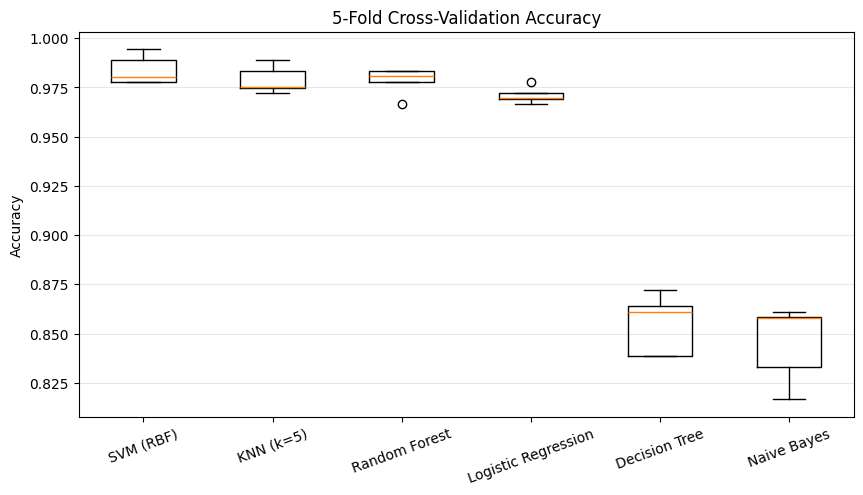

In [15]:
plt.figure(figsize=(10, 5))
order = cv_df.index
plt.boxplot([cv_scores[n] for n in order])
plt.xticks(range(1, len(order) + 1), order, rotation=20)
plt.title("5-Fold Cross-Validation Accuracy")
plt.ylabel("Accuracy")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [ ]:
#The dataset has 10 classes, so a confusion matrix shows exactly **which digits get confused** (not just how often).
#Error Rate = 1 - Accuracy**, so a model with 98% accuracy has a 2% error rate.
#**Precision** tells us how trustworthy a prediction for a digit is; **Recall** tells us how many real examples of that digit were found.
# SVM, Logistic Regression, KNN and Random Forest perform best (about 97-98% accuracy, 2-3% error rate). A single Decision Tree and Naive Bayes are much weaker (about 82-85%) because their assumptions suit pixel data less well.
# Digit 8 is the hardest for most models (and 9 for several), because their shapes overlap with other digits. Naive Bayes also struggles with 2 and 3.
# Cross-validation confirms the ranking of the algorithms and shows how stable each one is.